# Computer Graphics: Midpoint Ellipse Algorithm & 2D Transformations

This Jupyter Notebook implements:
1. **Midpoint Ellipse Algorithm** (scan-converting an ellipse with $a=6, b=4$ to obtain the 1st quadrant coordinates `(0,4), (1,4), (2,3), (3,3), (4,2), (5,1), (6,0)`).
2. **2D Geometric Transformations** using $3 \times 3$ homogeneous coordinate matrices:
   - Translation
   - Scaling (Uniform & Non-uniform)
   - Rotation
   - Reflection (about X-axis, Y-axis, and Origin / Both axes)
   - Shearing (X-shear and Y-shear)
   - Composite Transformation

## 1. Midpoint Ellipse Algorithm

### Mathematical Formulation
The implicit equation of an ellipse centered at $(0,0)$ is:
$$f(x, y) = b^2 x^2 + a^2 y^2 - a^2 b^2 = 0$$

The first quadrant is divided into two regions based on the slope $\frac{dy}{dx}$:
- **Region 1**: Slope magnitude $< 1$ (i.e. $2b^2 x < 2a^2 y$). We step in $+x$ and decide between $(x+1, y)$ and $(x+1, y-1)$.
  - Initial point: $(x_0, y_0) = (0, b)$
  - Initial decision parameter: $p_1 = b^2 - a^2 b + \frac{1}{4} a^2$
  - If $p_1 < 0$: $x = x + 1$, $p_1 = p_1 + 2b^2 x + b^2$
  - Else: $x = x + 1$, $y = y - 1$, $p_1 = p_1 + 2b^2 x - 2a^2 y + b^2$

- **Region 2**: Slope magnitude $\ge 1$ (i.e. $2b^2 x \ge 2a^2 y$). We step in $-y$ and decide between $(x, y-1)$ and $(x+1, y-1)$.
  - Initial decision parameter using last point $(x, y)$ of Region 1:
    $$p_2 = b^2 (x + 0.5)^2 + a^2 (y - 1)^2 - a^2 b^2$$
  - If $p_2 > 0$: $y = y - 1$, $p_2 = p_2 - 2a^2 y + a^2$
  - Else: $x = x + 1$, $y = y - 1$, $p_2 = p_2 + 2b^2 x - 2a^2 y + a^2$

Let us implement the exact step-by-step table and scan conversion.

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

def midpoint_ellipse(a, b):
    coords = []
    records = []
    
    x = 0
    y = b
    coords.append((x, y))
    
    # --- Region 1 ---
    # p1_0 = b^2 - a^2 * b + 0.25 * a^2
    p1 = b**2 - (a**2 * b) + 0.25 * (a**2)
    dx = 2 * b**2 * x
    dy = 2 * a**2 * y
    
    step = 1
    records.append({
        "Step": step, "Region": 1, "x": x, "y": y, 
        "2b^2x": dx, "2a^2y": dy, "p": p1
    })
    
    while dx < dy:
        x += 1
        dx += 2 * b**2
        if p1 < 0:
            p1 += dx + b**2
        else:
            y -= 1
            dy -= 2 * a**2
            p1 += dx - dy + b**2
        coords.append((x, y))
        step += 1
        records.append({
            "Step": step, "Region": 1, "x": x, "y": y,
            "2b^2x": dx, "2a^2y": dy, "p": p1
        })
    
    # --- Region 2 ---
    # Re-evaluate p2 at the transition midpoint
    p2 = (b**2) * ((x + 0.5)**2) + (a**2) * ((y - 1)**2) - (a**2 * b**2)
    
    while y > 0:
        y -= 1
        dy -= 2 * a**2
        if p2 > 0:
            p2 += a**2 - dy
        else:
            x += 1
            dx += 2 * b**2
            p2 += dx - dy + a**2
        coords.append((x, y))
        step += 1
        records.append({
            "Step": step, "Region": 2, "x": x, "y": y,
            "2b^2x": dx, "2a^2y": dy, "p": p2
        })
        
    return coords, pd.DataFrame(records)

# Run for a = 6, b = 4 (from lecture slides)
a, b = 6, 4
coordinates, df_steps = midpoint_ellipse(a, b)

print(f"First Quadrant Pixel Coordinates for a={a}, b={b}:")
print(coordinates)
df_steps

First Quadrant Pixel Coordinates for a=6, b=4:
[(0, 4), (1, 4), (2, 4), (3, 3), (4, 3), (5, 2), (6, 1), (6, 0)]


,Step,Region,x,y,2b^2x,2a^2y,p
0,1,1,0,4,0,288,-119.0
1,2,1,1,4,32,288,-71.0
2,3,1,2,4,64,288,9.0
3,4,1,3,3,96,216,-95.0
4,5,1,4,3,128,216,49.0
5,6,1,5,2,160,144,81.0
6,7,2,6,1,192,72,100.0
7,8,2,6,0,192,0,136.0


for the code First Quadrant Pixel Coordinates for a=6, b=4:
[(0, 4), (1, 4), (2, 4), (3, 3), (4, 3), (5, 2), (6, 1), (6, 0)]

In [13]:
def midpoint_ellipse_coordinates(a, b):
    coords = []
    
    # Starting point at top of the ellipse (0, b)
    x = 0
    y = b
    coords.append((x, y))
    
    # ------------------ Region 1 ------------------
    # Initial decision parameter: p1 = b^2 - a^2*b + 0.25*a^2
    p1 = (b ** 2) - (a ** 2 * b) + 0.25 * (a ** 2)
    dx = 2 * (b ** 2) * x
    dy = 2 * (a ** 2) * y
    
    while dx < dy:
        x += 1
        dx += 2 * (b ** 2)
        if p1 < 0:
            p1 += dx + (b ** 2)
        else:
            y -= 1
            dy -= 2 * (a ** 2)
            p1 += dx - dy + (b ** 2)
        coords.append((x, y))
        
    # ------------------ Region 2 ------------------
    # Initial decision parameter evaluated at the boundary midpoint
    p2 = (b ** 2) * ((x + 0.5) ** 2) + (a ** 2) * ((y - 1) ** 2) - ((a * b) ** 2)
    
    while y > 0:
        y -= 1
        dy -= 2 * (a ** 2)
        if p2 > 0:
            p2 += (a ** 2) - dy
        else:
            x += 1
            dx += 2 * (b ** 2)
            p2 += dx - dy + (a ** 2)
        coords.append((x, y))
        
    return coords

# Run for semi-major axis a = 6, semi-minor axis b = 4
a = 6
b = 4
pixels = midpoint_ellipse_coordinates(a, b)

print(f"First Quadrant Pixel Coordinates for a={a}, b={b}:")
print(pixels)

First Quadrant Pixel Coordinates for a=6, b=4:
[(0, 4), (1, 4), (2, 4), (3, 3), (4, 3), (5, 2), (6, 1), (6, 0)]


### Plotting the Ellipse (All 4 Quadrants via 4-way Symmetry)

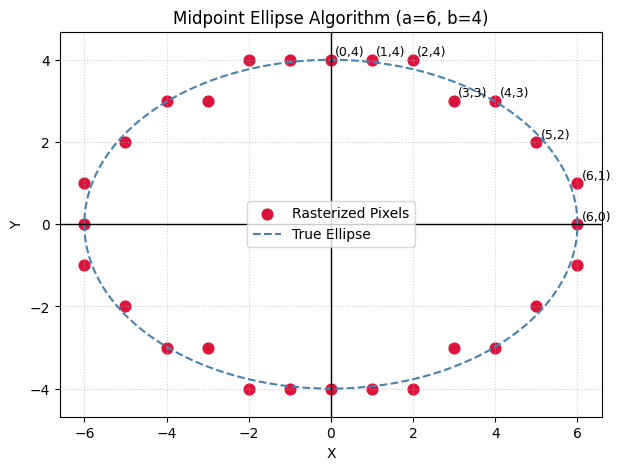

In [14]:
def plot_full_ellipse(q1_coords, a, b):
    full_pts = set()
    for x, y in q1_coords:
        full_pts.add((x, y))
        full_pts.add((-x, y))
        full_pts.add((x, -y))
        full_pts.add((-x, -y))
        
    xs, ys = zip(*full_pts)
    
    plt.figure(figsize=(7, 5))
    plt.scatter(xs, ys, color='crimson', s=60, label="Rasterized Pixels")
    for x, y in q1_coords:
        plt.annotate(f"({x},{y})", (x + 0.1, y + 0.1), fontsize=9)
        
    # Continuous theoretical curve for comparison
    theta = np.linspace(0, 2*np.pi, 200)
    plt.plot(a * np.cos(theta), b * np.sin(theta), '--', color='steelblue', label="True Ellipse")
    
    plt.axhline(0, color='black', linewidth=1)
    plt.axvline(0, color='black', linewidth=1)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.title(f"Midpoint Ellipse Algorithm (a={a}, b={b})")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.legend()
    plt.axis('equal')
    plt.show()

plot_full_ellipse(coordinates, a, b)

In [15]:
import numpy as np


def apply_transformation(matrix, points):
    arr = np.asarray(points, dtype=float)

    if arr.ndim == 1 and arr.size == 2:
        homog = np.array([arr[0], arr[1], 1.0], dtype=float)
        result = matrix @ homog
        return result[:2]

    if arr.ndim == 2 and arr.shape[1] == 2:
        homog = np.column_stack((arr, np.ones(arr.shape[0], dtype=float)))
        result = homog @ matrix.T
        return result[:, :2]

    raise ValueError("Expected a 2D point (x, y) or an array of points with shape (n, 2).")


def to_point(value):
    v = np.asarray(value, dtype=float)
    return tuple(np.round(v[:2], 4))


### (i) Translation
Shifts an object from one position to another along the x and y axes:
$$
\begin{bmatrix} x' \\ y' \\ 1 \end{bmatrix} = 
\begin{bmatrix} 
1 & 0 & t_x \\ 
0 & 1 & t_y \\ 
0 & 0 & 1 
\end{bmatrix} 
\begin{bmatrix} x \\ y \\ 1 \end{bmatrix}
$$

**Example from notes:** Translate point $(2, 3)$ by $(t_x, t_y) = (3, 5)$.
- $x' = 2 + 3 = 5$
- $y' = 3 + 5 = 8$

In [16]:
def translation_matrix(tx, ty):
    return np.array([
        [1, 0, tx],
        [0, 1, ty],
        [0, 0, 1]
    ], dtype=float)

# Verification with notebook example: Point (2, 3) translated by (3, 5)
T = translation_matrix(3, 5)
pt = np.array([2, 3])
res = apply_transformation(T, pt)
print("Translation Matrix:\n", T)
print(f"Translated point: {to_point(res)}")

Translation Matrix:
 [[1. 0. 3.]
 [0. 1. 5.]
 [0. 0. 1.]]
Translated point: (np.float64(5.0), np.float64(8.0))


### (ii) Scaling
Adjusts the size of an object by expanding or contracting it along the axes:
$$
\begin{bmatrix} x' \\ y' \\ 1 \end{bmatrix} = 
\begin{bmatrix} 
S_x & 0 & 0 \\ 
0 & S_y & 0 \\ 
0 & 0 & 1 
\end{bmatrix} 
\begin{bmatrix} x \\ y \\ 1 \end{bmatrix}
$$
- **Uniform Scaling**: $S_x = S_y$
- **Non-Uniform Scaling**: $S_x \neq S_y$

**Example from notes:** Scale point $(4, 3)$ with $S_x = 2, S_y = 3$.
- $x' = 4 \times 2 = 8$
- $y' = 3 \times 3 = 9$

In [17]:
def scaling_matrix(sx, sy):
    return np.array([
        [sx, 0,  0],
        [0,  sy, 0],
        [0,  0,  1]
    ], dtype=float)

# Verification with notebook example: Point (4, 3) scaled by (2, 3)
S = scaling_matrix(2, 3)
pt = np.array([4, 3])
res = apply_transformation(S, pt)
print("Scaling Matrix:\n", S)
print(f"Scaled point: {to_point(res)}")

Scaling Matrix:
 [[2. 0. 0.]
 [0. 3. 0.]
 [0. 0. 1.]]
Scaled point: (np.float64(8.0), np.float64(9.0))


### (iii) Rotation
Rotates an object around a pivot (default origin) by an angle $\theta$ (counter-clockwise):
$$
\begin{bmatrix} x' \\ y' \\ 1 \end{bmatrix} = 
\begin{bmatrix} 
\cos\theta & -\sin\theta & 0 \\ 
\sin\theta & \cos\theta & 0 \\ 
0 & 0 & 1 
\end{bmatrix} 
\begin{bmatrix} x \\ y \\ 1 \end{bmatrix}
$$

**Example from notes:** Rotate point $(1, 0)$ by $90^\circ$.
- $x' = 1 \cdot \cos 90^\circ - 0 \cdot \sin 90^\circ = 0$
- $y' = 1 \cdot \sin 90^\circ + 0 \cdot \cos 90^\circ = 1$

In [18]:
def rotation_matrix(degrees):
    rad = np.radians(degrees)
    c, s = np.cos(rad), np.sin(rad)
    return np.array([
        [c, -s, 0],
        [s,  c, 0],
        [0,  0, 1]
    ], dtype=float)

# Verification with notebook example: Point (1, 0) rotated by 90 degrees
R = rotation_matrix(90)
pt = np.array([1, 0])
res = apply_transformation(R, pt)
print("Rotation Matrix (90 deg):\n", np.round(R, 4))
print(f"Rotated point: {to_point(res)}")

Rotation Matrix (90 deg):
 [[ 0. -1.  0.]
 [ 1.  0.  0.]
 [ 0.  0.  1.]]
Rotated point: (np.float64(0.0), np.float64(1.0))


### (iv) Reflection
Creates a mirror image of an object across a specified axis:
1. **Across X-axis:** $(x' = x, y' = -y)$
   $$\begin{bmatrix} 1 & 0 & 0 \\ 0 & -1 & 0 \\ 0 & 0 & 1 \end{bmatrix}$$
2. **Across Y-axis:** $(x' = -x, y' = y)$
   $$\begin{bmatrix} -1 & 0 & 0 \\ 0 & 1 & 0 \\ 0 & 0 & 1 \end{bmatrix}$$
3. **Across Both Axes (Origin):** $(x' = -x, y' = -y)$
   $$\begin{bmatrix} -1 & 0 & 0 \\ 0 & -1 & 0 \\ 0 & 0 & 1 \end{bmatrix}$$

**Example from notes:** Reflecting $(3, 4)$ across the X-axis gives $(3, -4)$.

In [19]:
def reflection_matrix(axis='x'):
    if axis.lower() == 'x':
        return np.array([
            [ 1,  0, 0],
            [ 0, -1, 0],
            [ 0,  0, 1]
        ], dtype=float)
    elif axis.lower() == 'y':
        return np.array([
            [-1, 0, 0],
            [ 0, 1, 0],
            [ 0, 0, 1]
        ], dtype=float)
    elif axis.lower() in ['both', 'origin']:
        return np.array([
            [-1,  0, 0],
            [ 0, -1, 0],
            [ 0,  0, 1]
        ], dtype=float)
    else:
        raise ValueError("Axis must be 'x', 'y', or 'origin'/'both'")

# Verification with notebook example: Reflecting (3, 4) across x-axis
RefX = reflection_matrix('x')
pt = np.array([3, 4])
res = apply_transformation(RefX, pt)
print("Reflection across X-axis Matrix:\n", RefX)
print(f"Reflected point: {to_point(res)}")

Reflection across X-axis Matrix:
 [[ 1.  0.  0.]
 [ 0. -1.  0.]
 [ 0.  0.  1.]]
Reflected point: (np.float64(3.0), np.float64(-4.0))


### (v) Shearing
Distorts an object by shifting points along one axis proportional to their position along the other axis:
1. **X-Shear (parallel to X-axis):**
   $$x' = x + y \cdot Sh_x, \quad y' = y$$
   $$\begin{bmatrix} 1 & Sh_x & 0 \\ 0 & 1 & 0 \\ 0 & 0 & 1 \end{bmatrix}$$
2. **Y-Shear (parallel to Y-axis):**
   $$x' = x, \quad y' = y + x \cdot Sh_y$$
   $$\begin{bmatrix} 1 & 0 & 0 \\ Sh_y & 1 & 0 \\ 0 & 0 & 1 \end{bmatrix}$$

In [20]:
def shearing_matrix(shx=0, shy=0):
    return np.array([
        [1,   shx, 0],
        [shy, 1,   0],
        [0,   0,   1]
    ], dtype=float)

# Example: X-Shear with Sh_x = 2 on point (1, 2)
Sh = shearing_matrix(shx=2, shy=0)
pt = np.array([1, 2])
res = apply_transformation(Sh, pt)
print("Shearing Matrix (shx=2):\n", Sh)
print(f"Sheared point: {to_point(res)}")

Shearing Matrix (shx=2):
 [[1. 2. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
Sheared point: (np.float64(5.0), np.float64(2.0))


### (vi) Composite Transformation
A sequence of multiple transformations combined into one single matrix via matrix multiplication:
$$C = M_k \cdot M_{k-1} \cdots M_2 \cdot M_1$$

From lecture notes:
$$C = T \cdot S \quad (\text{Translation Matrix} \times \text{Scaling Matrix})$$

In [21]:
# Example: Scale by (2, 2) and then Translate by (3, 5)
S_mat = scaling_matrix(2, 2)
T_mat = translation_matrix(3, 5)
C_mat = T_mat @ S_mat

pt = np.array([2, 1])
res = apply_transformation(C_mat, pt)
print("Composite Matrix (T @ S):\n", C_mat)
print(f"Transformed Point: {to_point(res)}")

Composite Matrix (T @ S):
 [[2. 0. 3.]
 [0. 2. 5.]
 [0. 0. 1.]]
Transformed Point: (np.float64(7.0), np.float64(7.0))


### Visualizing All Transformations on a 2D Shape (Polygon)

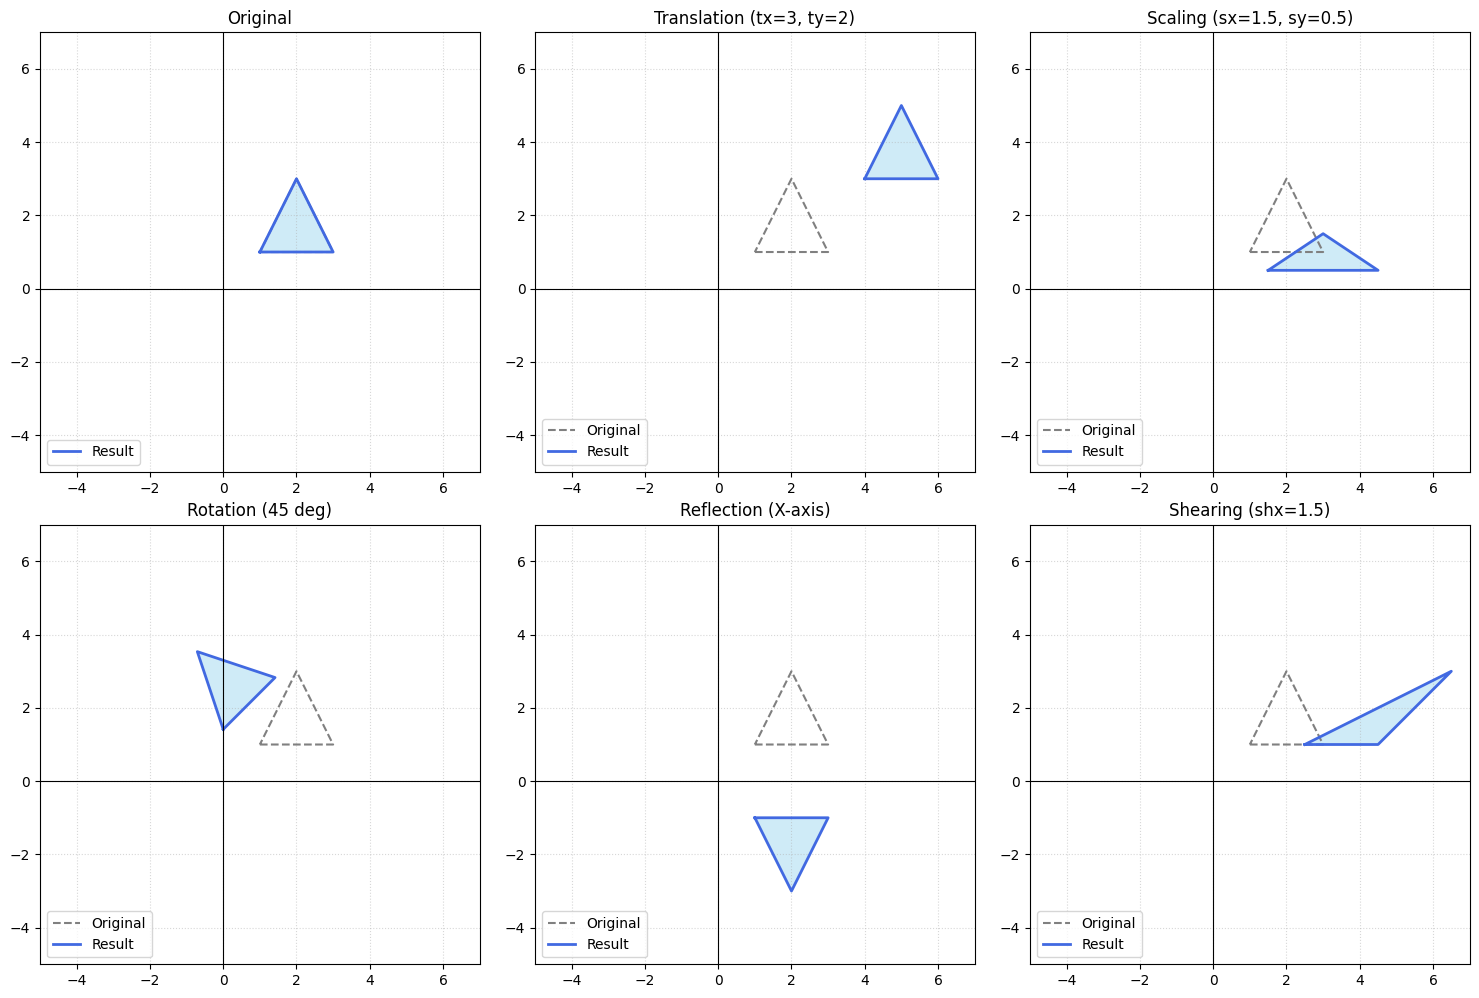

In [22]:
# Define a sample polygon: Triangle
triangle = np.array([
    [1, 1],
    [3, 1],
    [2, 3],
    [1, 1]  # closed loop
])

transformations = {
    "Original": np.eye(3),
    "Translation (tx=3, ty=2)": translation_matrix(3, 2),
    "Scaling (sx=1.5, sy=0.5)": scaling_matrix(1.5, 0.5),
    "Rotation (45 deg)": rotation_matrix(45),
    "Reflection (X-axis)": reflection_matrix('x'),
    "Shearing (shx=1.5)": shearing_matrix(shx=1.5, shy=0)
}

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for ax, (title, mat) in zip(axes, transformations.items()):
    t_tri = apply_transformation(mat, triangle)
    
    # Draw original for reference
    ax.plot(triangle[:, 0], triangle[:, 1], 'gray', linestyle='--', label='Original' if title != 'Original' else None)
    # Draw transformed
    ax.plot(t_tri[:, 0], t_tri[:, 1], 'royalblue', linewidth=2, label='Result')
    ax.fill(t_tri[:, 0], t_tri[:, 1], 'skyblue', alpha=0.4)
    
    ax.axhline(0, color='black', linewidth=0.8)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlim(-5, 7)
    ax.set_ylim(-5, 7)
    ax.set_aspect('equal')
    ax.grid(True, linestyle=':', alpha=0.5)
    ax.set_title(title)
    ax.legend(loc='lower left')

plt.tight_layout()
plt.show()


COMPUTER GRAPHICS: EXPLANATIONS OF CODE LOGIC


--------------------------------------------------------------------------------
1. MIDPOINT ELLIPSE ALGORITHM (CALCULATION & STEP TABLE)
--------------------------------------------------------------------------------
* import numpy as np, matplotlib.pyplot as plt, pandas as pd: Loads NumPy for mathematical and matrix operations, Matplotlib for plotting graphs, and Pandas to structure the step-by-step output table.
* x = 0, y = b: Initializes the starting pixel at the top vertex (0, b) of the ellipse in the first quadrant.
* p1 = b**2 - (a**2 * b) + 0.25 * (a**2): Computes the initial decision parameter for Region 1 to choose between the East pixel (x+1, y) and South-East pixel (x+1, y-1).
* while dx < dy: Continues iterating in Region 1 while the curve slope magnitude is less than 1 (2b^2x < 2a^2y), incrementing x by 1 at each step.
* p2 = (b**2) * ((x + 0.5)**2) + (a**2) * ((y - 1)**2) - (a**2 * b**2): Evaluates the initial decision parameter for Region 2 at the boundary midpoint where the slope reaches >= 1.
* while y > 0: Iterates through Region 2 until reaching the x-axis (y = 0), decrementing y by 1 at each step and deciding between (x, y-1) and (x+1, y-1).
* records.append(...) & pd.DataFrame(records): Logs the intermediate values at every step into a structured Pandas DataFrame table.

--------------------------------------------------------------------------------
2. PLOTTING THE FULL ELLIPSE (4-WAY SYMMETRY)
--------------------------------------------------------------------------------
* full_pts.add((x, y)), (-x, y), (x, -y), (-x, -y): Applies 4-way symmetry to reflect first-quadrant coordinates across both axes; using a set() automatically eliminates duplicate points lying on the axes.
* xs, ys = zip(*full_pts): Unpacks the list of (x, y) tuples into two separate X and Y coordinate lists for plotting.
* plt.plot(a * np.cos(theta), b * np.sin(theta), '--'): Plots the continuous theoretical ellipse using parametric equations so you can compare the rasterized pixels against the ideal curve.
* plt.axis('equal'): Enforces an equal aspect ratio on both axes so the ellipse renders with accurate geometric proportions.

--------------------------------------------------------------------------------
3. HOMOGENEOUS TRANSFORMATION HELPER FUNCTIONS
--------------------------------------------------------------------------------
* arr = np.asarray(points, dtype=float): Converts input lists, tuples, or arrays into a floating-point NumPy array for uniform processing.
* if arr.ndim == 1 and arr.size == 2: Checks whether the input is a single 2D point [x, y] (1D array of length 2).
* homog = np.array([arr[0], arr[1], 1.0], dtype=float): Appends 1.0 as the homogeneous coordinate (w = 1) to create a 3x1 vector [x, y, 1]^T so 3x3 matrix multiplication can perform translation.
* result = matrix @ homog: Performs matrix-vector multiplication using the @ operator to apply the 3x3 transformation matrix.
* ones = np.ones((arr.shape[0], 1)) & np.hstack([arr, ones]): Handles 2D polygons containing N vertices (shape N x 2) by attaching a column of 1s to form an N x 3 homogeneous coordinate matrix.
* transformed = (matrix @ homog_pts.T).T: Transposes the N x 3 points into column vectors (3 x N), multiplies by the 3 x 3 transformation matrix, and transposes back to N x 3.
* to_point(homogeneous_pt): Projects a 3x1 homogeneous vector [x', y', w'] back to 2D Cartesian coordinates [x'/w', y'/w'] by dividing the first two elements by the third element.

--------------------------------------------------------------------------------
4. 2D TRANSFORMATION MATRICES & VERIFICATIONS
--------------------------------------------------------------------------------
* translation_matrix(tx, ty): Places translation offsets tx and ty in the rightmost column so matrix multiplication evaluates x' = x + tx and y' = y + ty.
* scaling_matrix(sx, sy): Places scaling factors sx and sy along the main diagonal to compute x' = sx * x and y' = sy * y (uniform when sx == sy, non-uniform when sx != sy).
* rad = np.radians(degrees): Converts angles from degrees into radians because NumPy trigonometric functions (np.cos, np.sin) require radian inputs.
* np.round(..., 4): Rounds near-zero floating-point residuals (such as cos(90 deg) = 6.12e-17) to clean 0.0 values.
* reflection_matrix(axis): Negates the y-diagonal (-1) for X-axis reflection, negates the x-diagonal (-1) for Y-axis reflection, or negates both (-1) for reflection across the origin.
* shearing_matrix(shx, shy): Places shx in row 0, column 1 (x' = x + shx * y) and shy in row 1, column 0 (y' = y + shy * x) to slant the shape along the chosen axis.
* C_mat = T_mat @ S_mat: Combines multiple transformations into one composite matrix via matrix multiplication, applied right-to-left (Scaling first, then Translation).

--------------------------------------------------------------------------------
5. VISUALIZING ALL TRANSFORMATIONS ON A 2D POLYGON
--------------------------------------------------------------------------------
* [1, 1] repeated at the end of triangle: Closes the polygon perimeter so Matplotlib connects the final vertex (2, 3) back to the starting vertex (1, 1).
* np.eye(3): Generates a 3x3 identity matrix to plot the untransformed original triangle using the same loop structure.
* fig, axes = plt.subplots(4, 3, figsize=(15, 18)) & axes.flatten(): Creates a 4x3 grid of 12 subplots and flattens it into a 1D array so zip() can iterate over each subplot and transformation pair simultaneously.
* ax.fill(..., alpha=0.4): Fills the transformed triangle with semi-transparent color so the dashed gray original shape remains visible underneath for comparison.
* axes[-1].axis('off'): Hides the unused 12th subplot frame since 11 transformations are displayed.

